# 1. Image Arrays, Linear Combinations and 2D Transformations

Practice for module 1: an image is just a NumPy array. We build a small RGB image, normalize it,
blend two images with a linear combination, draw a 2D Gaussian, and transform points with matrices.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)
plt.rcParams["figure.dpi"] = 80

## 1.1 An RGB image as an array

Shape is `(height, width, 3)`, one byte (`uint8`, 0-255) per channel. We draw a tiny 8x8 "LED panel".

shape: (8, 8, 3) dtype: uint8
pixel (0, 0): [255   0   0]  pixel (7, 7): [255 255 255]


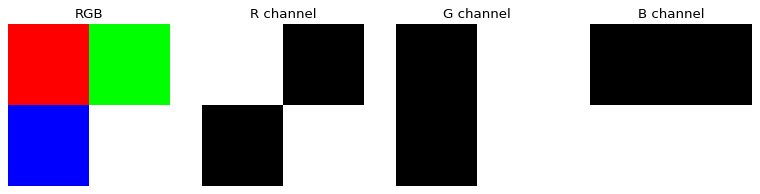

In [2]:
img = np.zeros((8, 8, 3), dtype=np.uint8)
img[:4, :4] = [255, 0, 0]      # red quadrant
img[:4, 4:] = [0, 255, 0]      # green quadrant
img[4:, :4] = [0, 0, 255]      # blue quadrant
img[4:, 4:] = [255, 255, 255]  # white quadrant

print("shape:", img.shape, "dtype:", img.dtype)
print("pixel (0, 0):", img[0, 0], " pixel (7, 7):", img[7, 7])

fig, axes = plt.subplots(1, 4, figsize=(12, 3))
axes[0].imshow(img, interpolation="nearest"); axes[0].set_title("RGB")
for ax, c, name in zip(axes[1:], range(3), ["R", "G", "B"]):
    ax.imshow(img[..., c], cmap="gray", vmin=0, vmax=255, interpolation="nearest")
    ax.set_title(f"{name} channel")
for ax in axes: ax.axis("off")
plt.show()

## 1.2 Normalization: `double` array → image range

Arbitrary floats are scaled to `[0, 1]` (for display) or `[0, 255]` (for `uint8`).

In [3]:
raw = np.random.default_rng(0).normal(loc=3.0, scale=2.0, size=(6, 6))
norm01 = (raw - raw.min()) / (raw.max() - raw.min())
as_u8 = (norm01 * 255).round().astype(np.uint8)

print(f"raw range:    [{raw.min():.2f}, {raw.max():.2f}]")
print(f"[0,1] range:  [{norm01.min():.2f}, {norm01.max():.2f}]")
print(f"uint8 range:  [{as_u8.min()}, {as_u8.max()}]")

raw range:    [-1.65, 5.73]
[0,1] range:  [0.00, 1.00]
uint8 range:  [0, 255]


## 1.3 Brightness and linear combination of images

`R(x, y) = a * I1(x, y) + b * I2(x, y)`. Multiplying by a factor > 1 makes an image brighter.
Values are clipped back to `[0, 255]`.

0.5*200 + 0.3*150 = 145.0


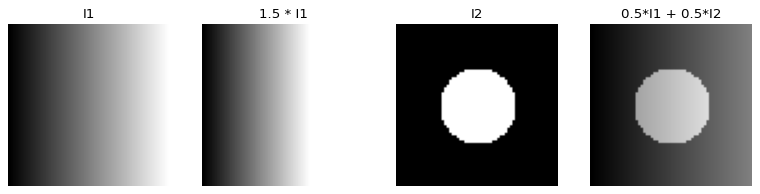

In [4]:
h, w = 64, 64
yy, xx = np.mgrid[0:h, 0:w]
I1 = (xx / (w - 1) * 255).astype(float)                                   # horizontal ramp
I2 = np.where((xx - 32) ** 2 + (yy - 32) ** 2 < 15 ** 2, 255.0, 0.0)      # white disk

def combine(a, I1, b, I2):
    return np.clip(a * I1 + b * I2, 0, 255)

brighter = np.clip(1.5 * I1, 0, 255)
blend = combine(0.5, I1, 0.5, I2)

# quiz check: a=0.5, b=0.3, I1=200, I2=150 -> 145
print("0.5*200 + 0.3*150 =", combine(0.5, 200, 0.3, 150))

fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for ax, im, t in zip(axes, [I1, brighter, I2, blend], ["I1", "1.5 * I1", "I2", "0.5*I1 + 0.5*I2"]):
    ax.imshow(im, cmap="gray", vmin=0, vmax=255); ax.set_title(t); ax.axis("off")
plt.show()

## 1.4 2D Gaussian

`G(x, y) = exp(-((x-μx)² + (y-μy)²) / (2σ²))`. μ sets the center, σ sets the spread
(same idea as the Excel heat map with Conditional Formatting).

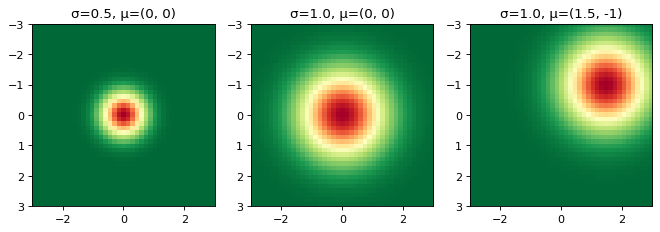

In [5]:
def gaussian2d(size, sigma, mu=(0.0, 0.0)):
    ax = np.linspace(-3, 3, size)
    x, y = np.meshgrid(ax, ax)
    return np.exp(-((x - mu[0]) ** 2 + (y - mu[1]) ** 2) / (2 * sigma ** 2))

fig, axes = plt.subplots(1, 3, figsize=(10, 3))
for ax, (sigma, mu) in zip(axes, [(0.5, (0, 0)), (1.0, (0, 0)), (1.0, (1.5, -1))]):
    ax.imshow(gaussian2d(41, sigma, mu), cmap="RdYlGn_r", extent=[-3, 3, 3, -3])
    ax.set_title(f"σ={sigma}, μ={mu}")
plt.show()

## 1.5 2D transformations with matrices

Points are stored as columns in homogeneous coordinates `(x, y, 1)`, so scaling, rotation and
translation are all 3x3 matrices and a group of points is transformed with one matrix multiplication.

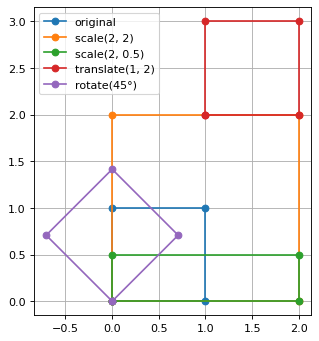

In [6]:
def scale(sx, sy):
    return np.array([[sx, 0, 0], [0, sy, 0], [0, 0, 1]], dtype=float)

def translate(tx, ty):
    return np.array([[1, 0, tx], [0, 1, ty], [0, 0, 1]], dtype=float)

def rotate(deg):
    t = np.deg2rad(deg)
    return np.array([[np.cos(t), -np.sin(t), 0], [np.sin(t), np.cos(t), 0], [0, 0, 1]])

# unit square, closed polygon, homogeneous columns
square = np.array([[0, 1, 1, 0, 0],
                   [0, 0, 1, 1, 0],
                   [1, 1, 1, 1, 1]], dtype=float)

shapes = {
    "original": square,
    "scale(2, 2)": scale(2, 2) @ square,
    "scale(2, 0.5)": scale(2, 0.5) @ square,
    "translate(1, 2)": translate(1, 2) @ square,
    "rotate(45°)": rotate(45) @ square,
}

fig, ax = plt.subplots(figsize=(5, 5))
for name, pts in shapes.items():
    ax.plot(pts[0], pts[1], marker="o", label=name)
ax.set_aspect("equal"); ax.grid(True); ax.legend(loc="upper left")
plt.show()

## 1.6 Order matters

Matrix multiplication is not commutative: "scale then translate" ≠ "translate then scale".

T @ S == S @ T ? False
T @ S =
 [[2. 0. 1.]
 [0. 2. 0.]
 [0. 0. 1.]]
S @ T =
 [[2. 0. 2.]
 [0. 2. 0.]
 [0. 0. 1.]]


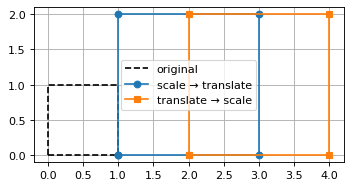

In [7]:
S, T = scale(2, 2), translate(1, 0)
a = T @ S @ square   # scale first, then translate
b = S @ T @ square   # translate first, then scale

print("T @ S == S @ T ?", np.allclose(T @ S, S @ T))
print("T @ S =\n", T @ S)
print("S @ T =\n", S @ T)

fig, ax = plt.subplots(figsize=(5, 4))
ax.plot(square[0], square[1], "k--", label="original")
ax.plot(a[0], a[1], marker="o", label="scale → translate")
ax.plot(b[0], b[1], marker="s", label="translate → scale")
ax.set_aspect("equal"); ax.grid(True); ax.legend()
plt.show()

## Summary

- An image is an array; RGB = 3 channels of 0-255.
- Normalization rescales arbitrary values to an image range.
- Linear combination: `a*I1 + b*I2` (blend, brightness).
- σ controls the spread of a Gaussian, μ its center.
- 2D transformations are matrix multiplications in homogeneous coordinates, and their order matters.